# **1. Perkenalan Dataset**

Dataset yang digunakan dalam proyek ini adalah data hasil pertandingan Mobile Legends: Bang Bang (MLBB) pada turnamen M5 World Championship.

Dataset ini mencakup berbagai atribut dari pertandingan seperti:
- Informasi tim (`Team`)
- Pilihan hero yang diban (`Ban`) dan role-nya (`Role Ban`)
- Pilihan hero yang dipick (`Pick`) dan role-nya (`Role Pick`)
- Label target: Penentuan pemain terbaik dalam pertandingan (`MVP`)

Tujuan dari eksperimen ini adalah menganalisis karakteristik data dan membangun alur preprocessing terstandarisasi untuk klasifikasi MVP.

# **2. Import Library**

Pada tahap ini, kita mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning.

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
print('Pustaka berhasil diimpor!')

Pustaka berhasil diimpor!


# **3. Memuat Dataset**

Pada tahap ini, dataset dimuat ke dalam DataFrame Pandas. Dataset mentah dibaca dari berkas `Full Match Results Data.csv`.

In [2]:
raw_path = '../namadataset_raw/Full Match Results Data.csv'
if not os.path.exists(raw_path):
    raw_path = 'Full Match Results Data.csv'
df = pd.read_csv(raw_path)
print(f'Dimensi dataset: {df.shape[0]} baris, {df.shape[1]} kolom')
df.head()

Dimensi dataset: 570 baris, 26 kolom


,Date,Match,Team,Ban,Players,Role Ban,Pick,Role Pick,Order Ban,Order Pick,...,Talent 3,K,D,A,Gold,Tower,Lord,Turtle,Buff Biru,Buff Merah
0,12-09-2023,1,Fire Flux Esports,Wanwan,Rosa,Marksman,Lylia,Marksman,1,1,...,Impure Rage,4,2,1.0,12.9K,6,1,3,11,8.0
1,12-09-2023,1,Fire Flux Esports,Arlott,Alien,Fighter/Assassin,Edith,Tank/Marksman,3,3,...,Quantum Charge,0,3,4.0,8.9K,6,1,3,11,8.0
2,12-09-2023,1,Fire Flux Esports,Hilda,Tienzy,Tank/Fighter,Martis,Fighter,5,3,...,Killing Spree,1,4,3.0,12.1K,6,1,3,11,8.0
3,12-09-2023,1,Fire Flux Esports,Angela,APEX47,Support,Lapu-Lapu,Fighter,8,6,...,Concussive Blast,2,4,1.0,10.8K,6,1,3,11,8.0
4,12-09-2023,1,Fire Flux Esports,Bruno,Sunshine,Marksman,Beatrix,Marksman,10,6,...,Quantum Charge,1,1,4.0,14.1K,6,1,3,11,8.0


# **4. Exploratory Data Analysis (EDA)**

Pada tahap ini dilakukan Exploratory Data Analysis (EDA) untuk memahami karakteristik data, memeriksa tipe data, missing values, dan distribusi target.

In [3]:
# 1. Informasi Struktur Data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 570 entries, 0 to 569
Data columns (total 26 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Date        570 non-null    object 
 1   Match       570 non-null    int64  
 2   Team        570 non-null    object 
 3   Ban         570 non-null    object 
 4   Players     570 non-null    object 
 5   Role Ban    570 non-null    object 
 6   Pick        570 non-null    object 
 7   Role Pick   570 non-null    object 
 8   Order Ban   570 non-null    int64  
 9   Order Pick  570 non-null    int64  
 10  MVP         570 non-null    int64  
 11  Time        570 non-null    object 
 12  Spell       570 non-null    object 
 13  Emblem      560 non-null    object 
 14  Talent 1    560 non-null    object 
 15  Talent 2    560 non-null    object 
 16  Talent 3    570 non-null    object 
 17  K           570 non-null    int64  
 18  D           570 non-null    int64  
 19  A           569 non-null    f

In [4]:
# 2. Pengecekan Missing Values dan Duplikasi
missing_vals = df.isnull().sum()
print('Kolom dengan missing values:')
print(missing_vals[missing_vals > 0])
print(f'\nJumlah baris duplikat: {df.duplicated().sum()}')

Kolom dengan missing values:
Emblem        10
Talent 1      10
Talent 2      10
A              1
Gold          20
Buff Biru     10
Buff Merah    20
dtype: int64

Jumlah baris duplikat: 0


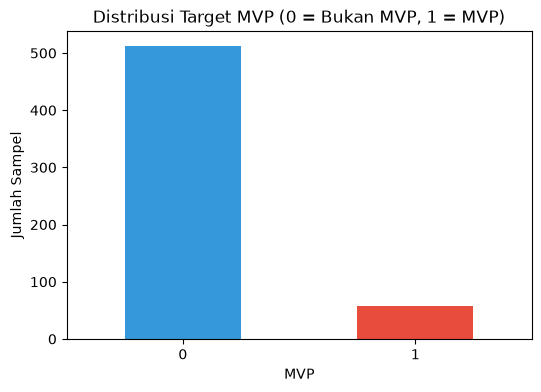

Distribusi target:
MVP
0    513
1     57
Name: count, dtype: int64


In [5]:
# 3. Distribusi Target MVP
plt.figure(figsize=(6, 4))
counts = df['MVP'].value_counts()
counts.plot(kind='bar', color=['#3498db', '#e74c3c'])
plt.title('Distribusi Target MVP (0 = Bukan MVP, 1 = MVP)')
plt.xlabel('MVP')
plt.ylabel('Jumlah Sampel')
plt.xticks(rotation=0)
plt.show()
print('Distribusi target:')
print(counts)

# **5. Data Preprocessing**

Pada tahap ini, data preprocessing dilakukan untuk membersihkan dan menyiapkan data sebelum digunakan dalam model machine learning:
1. Menghapus missing values
2. Memilih fitur relevan
3. Melakukan Label Encoding pada fitur kategorikal
4. Menyimpan dataset hasil preprocessing

In [6]:
# 1. Menghapus Missing Values
print(f'Jumlah baris sebelum cleaning: {len(df)}')
df_clean = df.dropna().copy()
print(f'Jumlah baris setelah cleaning: {len(df_clean)}')

Jumlah baris sebelum cleaning: 570
Jumlah baris setelah cleaning: 549


In [7]:
# 2. Seleksi Fitur dan Target
feature_cols = ['Team', 'Ban', 'Role Ban', 'Pick', 'Role Pick']
target_col = 'MVP'
df_subset = df_clean[feature_cols + [target_col]].copy()
df_subset.head()

,Team,Ban,Role Ban,Pick,Role Pick,MVP
0,Fire Flux Esports,Wanwan,Marksman,Lylia,Marksman,0
1,Fire Flux Esports,Arlott,Fighter/Assassin,Edith,Tank/Marksman,0
2,Fire Flux Esports,Hilda,Tank/Fighter,Martis,Fighter,0
3,Fire Flux Esports,Angela,Support,Lapu-Lapu,Fighter,0
4,Fire Flux Esports,Bruno,Marksman,Beatrix,Marksman,0


In [8]:
# 3. Encoding Fitur Kategorikal
encoders = {}
for col in feature_cols:
    le = LabelEncoder()
    df_subset[col] = le.fit_transform(df_subset[col].astype(str))
    encoders[col.lower().replace(' ', '_')] = le
    print(f'Fitur {col} di-encode ({len(le.classes_)} kategori unik)')

df_preprocessed = df_subset.rename(columns={
    'Team': 'team',
    'Ban': 'ban',
    'Role Ban': 'role_ban',
    'Pick': 'pick',
    'Role Pick': 'role_pick',
    'MVP': 'mvp'
})
df_preprocessed.head()

Fitur Team di-encode (8 kategori unik)
Fitur Ban di-encode (52 kategori unik)
Fitur Role Ban di-encode (16 kategori unik)
Fitur Pick di-encode (62 kategori unik)
Fitur Role Pick di-encode (16 kategori unik)


,team,ban,role_ban,pick,role_pick,mvp
0,4,50,7,42,7,0
1,4,2,3,14,14,0
2,4,23,13,43,2,0
3,4,1,8,39,2,0
4,4,7,7,5,7,0


In [9]:
# 4. Menyimpan Dataset Hasil Preprocessing
output_file = 'namadataset_preprocessing.csv'
df_preprocessed.to_csv(output_file, index=False)
joblib.dump(encoders, 'encoder_mappings.pkl')
print(f'Dataset hasil preprocessing berhasil disimpan ke: {output_file}')
print(f'Dimensi akhir dataset: {df_preprocessed.shape}')

Dataset hasil preprocessing berhasil disimpan ke: namadataset_preprocessing.csv
Dimensi akhir dataset: (549, 6)
